# Protocollo MQF — Prompt 0

Il **Prompt 0** inizializza il contesto generale, i Regimi A/B/C e le regole operative della linea studente.

Nel notebook docente non produce una cella quantitativa autonoma: il notebook documenta il **prodotto validato** del processo, non la trascrizione della conversazione con l'IA.

La sequenza metodologica di riferimento resta:

**Prompt 0 → Prompt 1 → Prompt 2 → Prompt 3 → prompt di tappa.**

Il Regime C non costituisce una fase ordinaria e viene attivato soltanto in presenza di una criticità specifica già individuata.

# Prompt 1 — Caso Aula: inquadramento vincolante

## SVB–ALM 2023 — Asset allocation, liquidità e valore dell'informazione

La Scheda Caso è la specifica vincolante. Il caso rappresenta in forma stilizzata una banca che deve scegliere **prima** della rivelazione dello scenario la composizione iniziale dell'attivo.

La struttura informativa è esclusivamente **two-stage**:

\[
x \longrightarrow s \longrightarrow (u_s,g_s).
\]

La decisione iniziale \(x\) è unica e comune agli scenari; funding di emergenza \(u_s\) e liquidità residua \(g_s\) sono scenario-specifici.

**Domanda quantitativa.** Quale composizione iniziale dell'attivo massimizza il risultato economico atteso tenendo conto di rendimenti, probabilità, fabbisogni di liquidità, liquidabilità degli attivi e costo del funding? Quanto valgono la modellizzazione stocastica e l'informazione perfetta?

### Quantità richieste

1. \(x^{SP}\), rendimento iniziale lordo, \(u_s^{SP},g_s^{SP}\), costo atteso del funding e \(z^{SP}\);
2. parametri medi, \(x^{EV}\), valore ottimo del problema medio, rivalutazione e \(z^{EV}\);
3. \(VSS\);
4. \(x_s^{WS}\), \(z_s^{WS}\), \(z^{WS}\);
5. \(EVPI\).

### Output richiesti

**Tabelle:** parametri; soluzione SP; Expected Value e rivalutazione; wait-and-see; confronto dei benchmark.

**Grafici:** composizione dell'attivo \(x^{SP}\) vs \(x^{EV}\); funding per scenario sotto \(x^{SP}\) e \(x^{EV}\).

### Controlli

Probabilità; bilancio iniziale; bounds; bilanci di liquidità scenario-specifici; successo del solver; \(x^{EV}\) mantenuta fissa nella rivalutazione; separazione dei problemi WS; ordinamento \(z^{EV}\le z^{SP}\le z^{WS}\); \(VSS,EVPI\ge0\).

# Prompt 2 — Flusso logico-teorico risolutivo

| Passo | Finalità risolutiva | Oggetto teorico | Applicazione nel caso | Output / controllo |
|---:|---|---|---|---|
| 1 | Identificare struttura informativa e decisioni | Programma stocastico a due stadi | \(x\) precede lo scenario; \(u_s,g_s\) seguono lo scenario | Classificazione variabili; probabilità |
| 2 | Costruire ricorso e forma estesa | Bilanci di secondo stadio; ricorso relativamente completo | Liquidità degli attivi + funding = fabbisogno + giacenza | Matrici solver; bilanci |
| 3 | Determinare SP | Massimizzazione del rendimento al netto del costo atteso del ricorso | Ottimizzazione congiunta di \(x,u_s,g_s\) | \(x^{SP},u_s^{SP},g_s^{SP},z^{SP}\) |
| 4 | Costruire e rivalutare EV | Problema medio; rivalutazione di \(x^{EV}\) | \(x^{EV}\) resta fissa; cambia solo il ricorso | Valore medio, \(z^{EV}\), VSS |
| 5 | Costruire WS | Informazione perfetta | Un problema separato per scenario | \(x_s^{WS},z_s^{WS},z^{WS},EVPI\) |
| 6 | Verificare e confrontare | \(z^{EV}\le z^{SP}\le z^{WS}\) | Confronto decisioni, funding e benchmark | Tabelle, grafici, controlli |

# Prompt 3 — Scomposizione in sei tappe input-output

| Tappa | Titolo | Obiettivo | Input | Operazione | Output | Controllo | Regime IA prevalente |
|---:|---|---|---|---|---|---|:---:|
| 1 | Struttura del modello e dati | Organizzare parametri e variabili | Scheda Caso | Definire dati e ordinamento solver | Tabella 1 | probabilità, parametri, bounds | A/B |
| 2 | Forma estesa e soluzione SP | Costruire e risolvere il programma stocastico | dati validati | Matrici, bounds, HiGHS | soluzione SP | status solver | B |
| 3 | Analisi e controlli SP | Rendere osservabili decisione iniziale e ricorso | soluzione SP | Estrarre risultati e residui | Tabella 2 | bilanci, bounds | B |
| 4 | Expected Value e rivalutazione | Costruire \(x^{EV}\) e valutarla correttamente | parametri medi e originari | Risolvere EV, fissare \(x^{EV}\), rivalutare | Tabella 3, \(z^{EV}\), VSS | nessuna riottimizzazione di \(x\) | B |
| 5 | Wait-and-see | Costruire informazione perfetta | scenari originari | Tre problemi separati | Tabella 4, \(z^{WS}\), EVPI | ponderazione corretta | B |
| 6 | Sintesi e controlli | Integrare i benchmark | output precedenti | Tabella 5, Figure 1–2, test finali | pacchetto quantitativo | ordinamento e segni | B |

Il Regime C non costituisce una tappa ordinaria.

# Prompt di Tappa 1 — Struttura del modello e dati

**Input:** Scheda Caso Aula, scenari \(N,P,R\), rendimenti, fabbisogni, coefficienti di liquidabilità, costi del funding e limiti sulle allocazioni.

**Operazione:** definire i parametri, fissare un ordinamento univoco delle variabili della forma estesa e predisporre una rappresentazione verificabile dei dati.

**Output:** Tabella 1 e schema delle variabili.

**Controlli:** somma delle probabilità; dimensioni coerenti; limiti \(x_3\le70\), \(x_4\le70\).

**Uso successivo:** costruzione della forma estesa SP.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog
from IPython.display import display, Markdown

pd.set_option("display.float_format", lambda x: f"{x:,.6f}")

assets = ["x1 - Cassa e riserve",
          "x2 - Titoli brevi",
          "x3 - Titoli lunghi",
          "x4 - Prestiti/impieghi"]
asset_keys = ["x1", "x2", "x3", "x4"]
scenarios = ["N", "P", "R"]

A0 = 100.0
c = np.array([0.010, 0.025, 0.040, 0.050], dtype=float)

p = np.array([0.60, 0.25, 0.15], dtype=float)
d = np.array([15.0, 35.0, 65.0], dtype=float)
kappa = np.array([0.01, 0.06, 0.25], dtype=float)

alpha = np.array([
    [1.00, 0.98, 0.85, 0.60],  # N
    [1.00, 0.95, 0.70, 0.40],  # P
    [1.00, 0.90, 0.50, 0.20],  # R
], dtype=float)

asset_upper = np.array([np.inf, np.inf, 70.0, 70.0])

assert np.isclose(p.sum(), 1.0)
assert alpha.shape == (3, 4)
assert len(c) == 4 and len(d) == len(p) == len(kappa) == 3

# Tabella 1: una rappresentazione compatta ma completa dei parametri.
tab1_assets = pd.DataFrame({
    "Tipo": "Attivo",
    "Elemento": asset_keys,
    "Descrizione": ["Cassa e riserve", "Titoli a breve scadenza",
                    "Titoli a lunga scadenza", "Prestiti e impieghi meno liquidi"],
    "Rendimento": c,
    "Limite_superiore": [np.nan, np.nan, 70.0, 70.0],
})

tab1_scen = pd.DataFrame({
    "Tipo": "Scenario",
    "Elemento": scenarios,
    "Descrizione": ["Condizioni normali", "Pressione sulla raccolta", "Run severo"],
    "Probabilita": p,
    "Fabbisogno_d": d,
    "Costo_funding_kappa": kappa,
})

tab1_alpha = pd.DataFrame(alpha, index=scenarios, columns=asset_keys)
tab1_alpha.index.name = "Scenario"

display(Markdown("### Tabella 1 — Parametri del problema"))
display(tab1_assets)
display(tab1_scen)
display(Markdown("**Coefficienti di liquidabilità \u03b1_{js}**"))
display(tab1_alpha)

print(f"Somma probabilità = {p.sum():.6f}")
print("Ordinamento SP: [x1, x2, x3, x4, u_N, g_N, u_P, g_P, u_R, g_R]")

### Tabella 1 — Parametri del problema

,Tipo,Elemento,Descrizione,Rendimento,Limite_superiore
0,Attivo,x1,Cassa e riserve,0.010000,NaN
1,Attivo,x2,Titoli a breve scadenza,0.025000,NaN
2,Attivo,x3,Titoli a lunga scadenza,0.040000,70.000000
3,Attivo,x4,Prestiti e impieghi meno liquidi,0.050000,70.000000


,Tipo,Elemento,Descrizione,Probabilita,Fabbisogno_d,Costo_funding_kappa
0,Scenario,N,Condizioni normali,0.600000,15.000000,0.010000
1,Scenario,P,Pressione sulla raccolta,0.250000,35.000000,0.060000
2,Scenario,R,Run severo,0.150000,65.000000,0.250000


**Coefficienti di liquidabilità α_{js}**

,x1,x2,x3,x4
Scenario,,,,
N,1.000000,0.980000,0.850000,0.600000
P,1.000000,0.950000,0.700000,0.400000
R,1.000000,0.900000,0.500000,0.200000


Somma probabilità = 1.000000
Ordinamento SP: [x1, x2, x3, x4, u_N, g_N, u_P, g_P, u_R, g_R]


# Prompt di Tappa 2 — Forma estesa e soluzione SP

**Input:** parametri validati e ordinamento delle variabili.

**Operazione:** costruire la funzione obiettivo, il vincolo di bilancio iniziale e i tre bilanci di liquidità. Poiché `linprog` minimizza, si minimizza l'opposto del risultato economico.

**Output:** soluzione della forma estesa con `scipy.optimize.linprog(method="highs")`.

**Controllo:** successo del solver e coerenza dell'ordinamento delle variabili.

In [2]:
# Variabili:
# [x1, x2, x3, x4, u_N, g_N, u_P, g_P, u_R, g_R]

n_x = 4
n_s = len(scenarios)
n_var = n_x + 2 * n_s

var_names = asset_keys.copy()
for s in scenarios:
    var_names += [f"u_{s}", f"g_{s}"]

# Funzione obiettivo di minimizzazione:
# -c'x + sum_s p_s * kappa_s * u_s
obj_sp = np.zeros(n_var)
obj_sp[:n_x] = -c
for i in range(n_s):
    obj_sp[n_x + 2*i] = p[i] * kappa[i]

# Uguaglianze: bilancio iniziale + bilanci di liquidità.
A_eq_sp = []
b_eq_sp = []

row = np.zeros(n_var)
row[:n_x] = 1.0
A_eq_sp.append(row)
b_eq_sp.append(A0)

for i in range(n_s):
    row = np.zeros(n_var)
    row[:n_x] = alpha[i]
    row[n_x + 2*i] = 1.0      # + u_s
    row[n_x + 2*i + 1] = -1.0 # - g_s
    A_eq_sp.append(row)
    b_eq_sp.append(d[i])

A_eq_sp = np.array(A_eq_sp)
b_eq_sp = np.array(b_eq_sp)

bounds_sp = [
    (0.0, None),  # x1
    (0.0, None),  # x2
    (0.0, 70.0),  # x3
    (0.0, 70.0),  # x4
] + [(0.0, None), (0.0, None)] * n_s

res_sp = linprog(
    c=obj_sp,
    A_eq=A_eq_sp,
    b_eq=b_eq_sp,
    bounds=bounds_sp,
    method="highs"
)

print("Solver SP:", res_sp.message)
assert res_sp.success, res_sp.message

sol_sp = pd.Series(res_sp.x, index=var_names, name="Valore")
display(sol_sp.to_frame())

Solver SP: Optimization terminated successfully. (HiGHS Status 7: Optimal)


,Valore
x1,0.000000
x2,30.000000
x3,70.000000
x4,0.000000
u_N,0.000000
g_N,73.900000
u_P,0.000000
g_P,42.500000
u_R,3.000000
g_R,0.000000


# Prompt di Tappa 3 — Analisi e controlli della soluzione SP

**Input:** soluzione della forma estesa.

**Operazione:** estrarre \(x^{SP}\), funding e giacenze, calcolare rendimento iniziale lordo, costo atteso del funding, \(z^{SP}\), liquidità ottenibile dagli attivi e residui dei bilanci.

**Output:** Tabella 2.

**Controlli:** bilancio iniziale, bounds, bilanci scenario-specifici, non negatività del ricorso.

In [3]:
x_sp = res_sp.x[:4].copy()
u_sp = np.array([res_sp.x[4 + 2*i] for i in range(n_s)])
g_sp = np.array([res_sp.x[5 + 2*i] for i in range(n_s)])

liq_sp = alpha @ x_sp
gross_sp = float(c @ x_sp)
funding_cost_s_sp = kappa * u_sp
expected_funding_cost_sp = float(p @ funding_cost_s_sp)
z_sp = gross_sp - expected_funding_cost_sp

balance_residual_sp = liq_sp + u_sp - d - g_sp

tab2 = pd.DataFrame({
    "Scenario": scenarios,
    "x1_SP": x_sp[0],
    "x2_SP": x_sp[1],
    "x3_SP": x_sp[2],
    "x4_SP": x_sp[3],
    "Liquidita_da_attivi": liq_sp,
    "u_SP": u_sp,
    "g_SP": g_sp,
    "Costo_funding_scenario": funding_cost_s_sp,
    "Residuo_bilancio": balance_residual_sp,
})

display(Markdown("### Tabella 2 — Soluzione stocastica"))
display(tab2)

print("x^SP =", np.round(x_sp, 8))
print(f"Rendimento iniziale lordo = {gross_sp:.6f}")
print(f"Costo atteso del funding = {expected_funding_cost_sp:.6f}")
print(f"z^SP = {z_sp:.6f}")

assert np.isclose(x_sp.sum(), A0)
assert np.all(x_sp >= -1e-9)
assert x_sp[2] <= 70 + 1e-9 and x_sp[3] <= 70 + 1e-9
assert np.all(u_sp >= -1e-9) and np.all(g_sp >= -1e-9)
assert np.max(np.abs(balance_residual_sp)) < 1e-8

### Tabella 2 — Soluzione stocastica

,Scenario,x1_SP,x2_SP,x3_SP,x4_SP,Liquidita_da_attivi,u_SP,g_SP,Costo_funding_scenario,Residuo_bilancio
0,N,0.000000,30.000000,70.000000,0.000000,88.900000,0.000000,73.900000,0.000000,0.000000
1,P,0.000000,30.000000,70.000000,0.000000,77.500000,0.000000,42.500000,0.000000,0.000000
2,R,0.000000,30.000000,70.000000,0.000000,62.000000,3.000000,0.000000,0.750000,0.000000


x^SP = [ 0. 30. 70.  0.]
Rendimento iniziale lordo = 3.550000
Costo atteso del funding = 0.112500
z^SP = 3.437500


# Prompt di Tappa 4 — Expected Value e rivalutazione

**Input:** parametri originari e probabilità.

**Operazione:** calcolare \(\bar d\), \(\bar\alpha_j\), \(\bar\kappa\), risolvere il problema deterministico medio e ottenere \(x^{EV}\). Successivamente **fissare** \(x^{EV}\) e rivalutarla nei tre scenari originari, riottimizzando soltanto il ricorso.

**Output:** valore ottimo del problema medio, \(x^{EV}\), ricorsi di rivalutazione, \(z^{EV}\), VSS e Tabella 3.

**Controllo:** il valore del problema medio non deve essere confuso con \(z^{EV}\).

In [4]:
bar_d = float(p @ d)
bar_alpha = p @ alpha
bar_kappa = float(p @ kappa)

# Problema deterministico medio:
# variabili [x1,x2,x3,x4,u,g]
obj_ev = np.zeros(6)
obj_ev[:4] = -c
obj_ev[4] = bar_kappa

A_eq_ev = np.zeros((2, 6))
b_eq_ev = np.array([A0, bar_d], dtype=float)

A_eq_ev[0, :4] = 1.0
A_eq_ev[1, :4] = bar_alpha
A_eq_ev[1, 4] = 1.0
A_eq_ev[1, 5] = -1.0

bounds_ev = [
    (0.0, None), (0.0, None), (0.0, 70.0), (0.0, 70.0),
    (0.0, None), (0.0, None)
]

res_ev = linprog(
    c=obj_ev,
    A_eq=A_eq_ev,
    b_eq=b_eq_ev,
    bounds=bounds_ev,
    method="highs"
)
assert res_ev.success, res_ev.message

x_ev = res_ev.x[:4].copy()
value_mean_problem = float(-res_ev.fun)

# Rivalutazione di x^EV negli scenari originari:
# x rimane fissa. Con funding illimitato, per ciascuno scenario
# u_s = max(d_s - alpha_s x, 0) e g_s = max(alpha_s x - d_s, 0).
liq_ev = alpha @ x_ev
u_ev = np.maximum(d - liq_ev, 0.0)
g_ev = np.maximum(liq_ev - d, 0.0)

gross_ev = float(c @ x_ev)
funding_cost_s_ev = kappa * u_ev
expected_funding_cost_ev = float(p @ funding_cost_s_ev)
z_ev = gross_ev - expected_funding_cost_ev
vss = z_sp - z_ev

mean_params = pd.DataFrame({
    "Parametro": ["d_bar", "kappa_bar", "alpha_bar_x1", "alpha_bar_x2",
                  "alpha_bar_x3", "alpha_bar_x4"],
    "Valore": [bar_d, bar_kappa, *bar_alpha]
})

tab3_eval = pd.DataFrame({
    "Scenario": scenarios,
    "x1_EV": x_ev[0],
    "x2_EV": x_ev[1],
    "x3_EV": x_ev[2],
    "x4_EV": x_ev[3],
    "Liquidita_da_attivi": liq_ev,
    "u_EV": u_ev,
    "g_EV": g_ev,
    "Costo_funding_scenario": funding_cost_s_ev,
})

display(Markdown("### Tabella 3 — Expected Value e rivalutazione"))
display(Markdown("**Parametri medi**"))
display(mean_params)
display(Markdown(r"**Rivalutazione di \(x^{EV}\) negli scenari originari**"))
display(tab3_eval)

print("x^EV =", np.round(x_ev, 8))
print(f"Valore ottimo del problema deterministico medio = {value_mean_problem:.6f}")
print(f"Rendimento iniziale lordo di x^EV = {gross_ev:.6f}")
print(f"Costo atteso del funding dopo rivalutazione = {expected_funding_cost_ev:.6f}")
print(f"z^EV = {z_ev:.6f}")
print(f"VSS = {vss:.6f}")

assert np.isclose(x_ev.sum(), A0)
assert z_ev <= z_sp + 1e-9
assert vss >= -1e-9

### Tabella 3 — Expected Value e rivalutazione

**Parametri medi**

,Parametro,Valore
0,d_bar,27.500000
1,kappa_bar,0.058500
2,alpha_bar_x1,1.000000
3,alpha_bar_x2,0.960500
4,alpha_bar_x3,0.760000
5,alpha_bar_x4,0.490000


**Rivalutazione di \(x^{EV}\) negli scenari originari**

,Scenario,x1_EV,x2_EV,x3_EV,x4_EV,Liquidita_da_attivi,u_EV,g_EV,Costo_funding_scenario
0,N,0.000000,0.000000,30.000000,70.000000,67.500000,0.000000,52.500000,0.000000
1,P,0.000000,0.000000,30.000000,70.000000,49.000000,0.000000,14.000000,0.000000
2,R,0.000000,0.000000,30.000000,70.000000,29.000000,36.000000,0.000000,9.000000


x^EV = [ 0.  0. 30. 70.]
Valore ottimo del problema deterministico medio = 4.700000
Rendimento iniziale lordo di x^EV = 4.700000
Costo atteso del funding dopo rivalutazione = 1.350000
z^EV = 3.350000
VSS = 0.087500


# Prompt di Tappa 5 — Wait-and-see e informazione perfetta

**Input:** tre scenari originari.

**Operazione:** risolvere un problema distinto per ciascuno scenario, consentendo alla decisione iniziale \(x_s^{WS}\) di essere scelta conoscendo anticipatamente \(s\).

**Output:** \(x_s^{WS}\), ricorsi, \(z_s^{WS}\), \(z^{WS}\), EVPI e Tabella 4.

**Controllo:** i tre problemi sono separati e \(z^{WS}\) è la media ponderata dei valori scenario-specifici.

In [5]:
def solve_ws_scenario(i):
    # Variabili [x1,x2,x3,x4,u,g]
    obj = np.zeros(6)
    obj[:4] = -c
    obj[4] = kappa[i]

    Aeq = np.zeros((2, 6))
    beq = np.array([A0, d[i]], dtype=float)

    Aeq[0, :4] = 1.0
    Aeq[1, :4] = alpha[i]
    Aeq[1, 4] = 1.0
    Aeq[1, 5] = -1.0

    res = linprog(
        c=obj,
        A_eq=Aeq,
        b_eq=beq,
        bounds=bounds_ev,
        method="highs"
    )
    if not res.success:
        raise RuntimeError(f"WS {scenarios[i]} non risolto: {res.message}")
    return res

ws_results = [solve_ws_scenario(i) for i in range(n_s)]

x_ws = np.vstack([r.x[:4] for r in ws_results])
u_ws = np.array([r.x[4] for r in ws_results])
g_ws = np.array([r.x[5] for r in ws_results])
z_ws_s = np.array([-r.fun for r in ws_results])

z_ws = float(p @ z_ws_s)
evpi = z_ws - z_sp

tab4 = pd.DataFrame({
    "Scenario": scenarios,
    "Probabilita": p,
    "x1_WS": x_ws[:, 0],
    "x2_WS": x_ws[:, 1],
    "x3_WS": x_ws[:, 2],
    "x4_WS": x_ws[:, 3],
    "u_WS": u_ws,
    "g_WS": g_ws,
    "z_WS_scenario": z_ws_s,
    "Contributo_a_z_WS": p * z_ws_s,
})

display(Markdown("### Tabella 4 — Wait-and-see"))
display(tab4)

print(f"z^WS = {z_ws:.6f}")
print(f"EVPI = {evpi:.6f}")

assert np.all([r.success for r in ws_results])
assert np.isclose(z_ws, np.sum(p * z_ws_s))
assert z_sp <= z_ws + 1e-9
assert evpi >= -1e-9

### Tabella 4 — Wait-and-see

,Scenario,Probabilita,x1_WS,x2_WS,x3_WS,x4_WS,u_WS,g_WS,z_WS_scenario,Contributo_a_z_WS
0,N,0.600000,0.000000,0.000000,30.000000,70.000000,0.000000,52.500000,4.700000,2.820000
1,P,0.250000,0.000000,0.000000,30.000000,70.000000,0.000000,14.000000,4.700000,1.175000
2,R,0.150000,0.000000,37.500000,62.500000,0.000000,0.000000,0.000000,3.437500,0.515625


z^WS = 4.510625
EVPI = 1.073125


# Prompt di Tappa 6 — Confronto, grafici e controlli conclusivi

**Input:** risultati SP, EV rivalutato e WS.

**Operazione:** costruire la tabella finale dei benchmark, i due grafici richiesti e una batteria di controlli numerici/logici.

**Output:** Tabella 5, Figura 1, Figura 2 e controlli conclusivi.

**Controllo:** \(z^{EV}\le z^{SP}\le z^{WS}\), \(VSS\ge0\), \(EVPI\ge0\), completezza degli output.

### Tabella 5 — Confronto dei benchmark

,Benchmark,Valore,Interpretazione
0,EV rivalutato,3.350000,Valore atteso della decisione ottenuta dal pro...
1,SP,3.437500,Valore ottimo del programma stocastico
2,WS,4.510625,Valore atteso con informazione perfetta
3,VSS,0.087500,Valore della soluzione stocastica rispetto a EV
4,EVPI,1.073125,Valore atteso dell'informazione perfetta


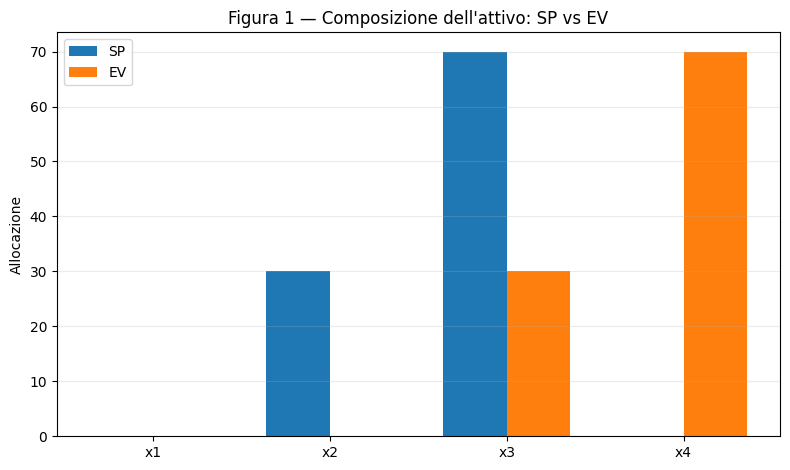

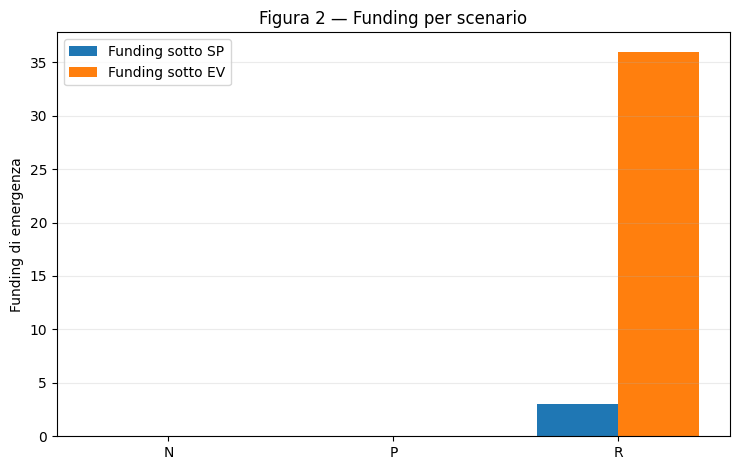

### Controlli conclusivi

,Controllo,Esito
0,Somma probabilità = 1,True
1,Bilancio iniziale SP,True
2,x3_SP <= 70,True
3,x4_SP <= 70,True
4,Ricorsi SP non negativi,True
5,Bilanci SP,True
6,xEV mantenuta fissa in rivalutazione,True
7,Problemi WS separati e risolti,True
8,zEV <= zSP,True
9,zSP <= zWS,True


Tutti i controlli conclusivi sono soddisfatti.


In [6]:
tab5 = pd.DataFrame({
    "Benchmark": ["EV rivalutato", "SP", "WS", "VSS", "EVPI"],
    "Valore": [z_ev, z_sp, z_ws, vss, evpi],
    "Interpretazione": [
        "Valore atteso della decisione ottenuta dal problema medio",
        "Valore ottimo del programma stocastico",
        "Valore atteso con informazione perfetta",
        "Valore della soluzione stocastica rispetto a EV",
        "Valore atteso dell'informazione perfetta",
    ],
})

display(Markdown("### Tabella 5 — Confronto dei benchmark"))
display(tab5)

# Figura 1 — composizione dell'attivo
pos = np.arange(4)
width = 0.36

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.bar(pos - width/2, x_sp, width, label="SP")
ax.bar(pos + width/2, x_ev, width, label="EV")
ax.set_xticks(pos)
ax.set_xticklabels(asset_keys)
ax.set_ylabel("Allocazione")
ax.set_title("Figura 1 — Composizione dell'attivo: SP vs EV")
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# Figura 2 — funding per scenario
pos = np.arange(len(scenarios))

fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.bar(pos - width/2, u_sp, width, label="Funding sotto SP")
ax.bar(pos + width/2, u_ev, width, label="Funding sotto EV")
ax.set_xticks(pos)
ax.set_xticklabels(scenarios)
ax.set_ylabel("Funding di emergenza")
ax.set_title("Figura 2 — Funding per scenario")
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# Controlli conclusivi
controls = pd.DataFrame({
    "Controllo": [
        "Somma probabilità = 1",
        "Bilancio iniziale SP",
        "x3_SP <= 70",
        "x4_SP <= 70",
        "Ricorsi SP non negativi",
        "Bilanci SP",
        "xEV mantenuta fissa in rivalutazione",
        "Problemi WS separati e risolti",
        "zEV <= zSP",
        "zSP <= zWS",
        "VSS >= 0",
        "EVPI >= 0",
    ],
    "Esito": [
        np.isclose(p.sum(), 1.0),
        np.isclose(x_sp.sum(), A0),
        x_sp[2] <= 70 + 1e-9,
        x_sp[3] <= 70 + 1e-9,
        np.all(u_sp >= -1e-9) and np.all(g_sp >= -1e-9),
        np.max(np.abs(balance_residual_sp)) < 1e-8,
        all(np.allclose(tab3_eval[[f"x{i}_EV" for i in range(1,5)]].iloc[j].to_numpy(), x_ev)
            for j in range(len(scenarios))),
        all(r.success for r in ws_results),
        z_ev <= z_sp + 1e-9,
        z_sp <= z_ws + 1e-9,
        vss >= -1e-9,
        evpi >= -1e-9,
    ],
})

display(Markdown("### Controlli conclusivi"))
display(controls)

if not controls["Esito"].all():
    raise AssertionError("Almeno un controllo conclusivo non è soddisfatto.")

print("Tutti i controlli conclusivi sono soddisfatti.")

# Interpretazione finanziaria docente di riferimento

La soluzione stocastica privilegia una composizione più liquida rispetto alla decisione costruita sui parametri medi. In particolare, la decisione SP concentra l'attivo su titoli brevi e titoli lunghi, mentre la decisione EV sposta risorse verso prestiti e impieghi meno liquidi, caratterizzati da rendimento maggiore ma minore capacità di generare liquidità nello scenario severo.

Il confronto deve essere letto separando tre grandezze:

1. **rendimento iniziale lordo** della composizione scelta;
2. **costo atteso del funding di emergenza** indotto dalla stessa scelta nei tre scenari;
3. **valore finale del benchmark** dopo il ricorso.

La decisione EV presenta un rendimento iniziale lordo più elevato, ma nello scenario \(R\) richiede un funding di emergenza molto maggiore. Dopo la rivalutazione negli scenari originari, questo costo riduce il valore di \(x^{EV}\) sotto il valore della soluzione stocastica.

Il VSS misura il vantaggio derivante dall'utilizzo esplicito della distribuzione degli scenari nel problema decisionale. L'EVPI misura invece quanto aumenterebbe il valore atteso se lo scenario fosse noto prima della scelta iniziale.

Il benchmark WS non rappresenta una strategia implementabile ex ante: consente una diversa decisione iniziale in ciascuno scenario e serve esclusivamente come riferimento per misurare il valore dell'informazione perfetta.

# Limiti del modello

Il caso è deliberatamente stilizzato. Non ricostruisce quantitativamente Silicon Valley Bank e non modella:

- una corsa agli sportelli endogena;
- capitale regolamentare o insolvenza;
- distinzione HTM/AFS;
- duration e mark-to-market espliciti;
- feedback tra decisioni e probabilità degli scenari;
- strumenti pubblici di emergenza;
- costi non lineari del funding;
- dinamiche multistadio o informazione progressiva.

Il funding è assunto illimitato; il ricorso è quindi relativamente completo nel modello assegnato.

# Sintesi finale

Il notebook implementa il Caso Aula della Lezione 16 nel framework **two-stage** richiesto:

- un'unica decisione iniziale \(x\) comune agli scenari;
- ricorso scenario-specifico \((u_s,g_s)\);
- soluzione SP;
- problema EV e corretta rivalutazione di \(x^{EV}\);
- tre problemi WS separati;
- VSS ed EVPI;
- cinque tabelle;
- due grafici;
- controlli numerici e logici conclusivi.

Gli output computazionali sono prodotti direttamente nel notebook e non vengono esportati automaticamente in file esterni.